# TP1 : Génération de variables aléatoires

## G3 SDI - Estimation Avancée

Dans ce TP, on s'intéresse à la génération de variables aléatoires, i.e., la capacité de produire des échantillons finis de variables ou vecteurs aléatoires d'une loi donnée.
* Dans un premier temps, on suppose que l'on dispose d'un générateur de loi uniforme sur $[0,1]$ (avec Numpy, il est donné par `np.random.rand`). À partir de ce générateur, le but sera de générer des échantillons d'autres lois avec des méthodes simples, notamment la méthode de la transformée inverse.
* Dans un deuxième temps, on étudiera des méthodes plus sophistiquées (acceptation-rejet, échantillonnage d'importance).

Pour chaque question, **justifier brièvement la solution puis l'implémenter**. **Comparer avec la densité théorique** à l'aide d'histogrammes ou de KDE.

### Instructions

1. Renommez votre notebook sous la forme `tp1_Nom1_Nom2.ipynb`. 

2. Votre code, ainsi que toute sortie du code, doivent être commentés !

3. Déposez votre notebook sur Moodle dans la section prévue à cet effet avant la date limite.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Compte-rendu écrit par [nom1], [nom2], date.
</div>

In [35]:
# Importing usual libraries
import numpy as np
from matplotlib import pyplot as plt
from sklearn.neighbors import KernelDensity

### Exercice 1 - Pour commencer : lois uniformes

**Q1**. À partir de $N$ échantillons d'une loi uniforme sur l'intervalle $[0,1]$, comment obtenir $N$ échantillons d'une loi uniforme sur l'intervalle $[a,b]$ ?

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On applique à chaque échantillon $U_n$ la transformation affine bijective
$$
f(t) = a + (b-a)\,t = (1-t)\,a + t\,b .
$$

La fonction de répartition de la loi uniforme sur $[a,b]$ est $F(x) = \frac{x-a}{b-a}$ pour $x \in [a,b]$, dont l'inverse est exactement $F^{-1}(u) = a + (b-a)\,u = f(u)$. D'après la méthode de la transformée inverse, $V_n = f(U_n)$ suit donc la loi uniforme sur $[a,b]$, de densité $\frac{1}{b-a}\,\mathbb{1}_{[a,b]}$.

</div>

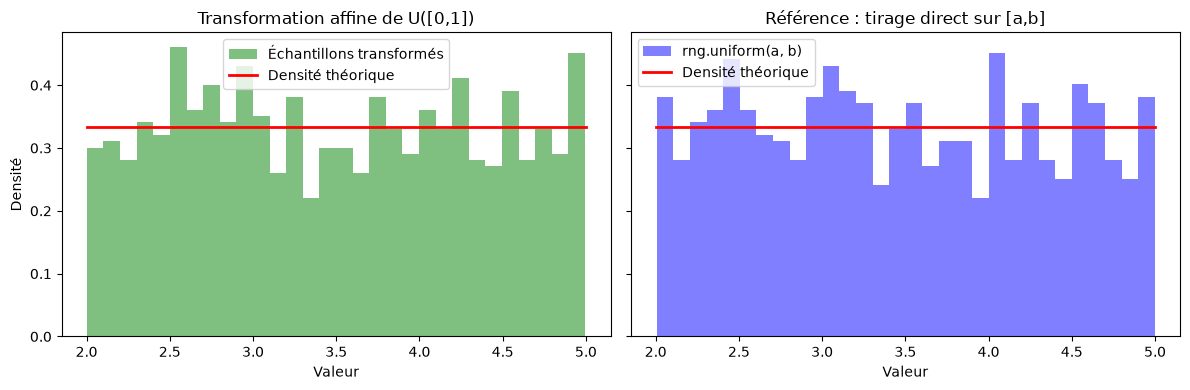

In [36]:
rng = np.random.default_rng(seed=67)
n = 1000
a, b = 2, 5

def resample(U, a, b):
    """Envoie des échantillons uniformes sur [0,1] sur l'intervalle [a,b]."""
    return a + (b - a) * U

# Échantillons uniformes sur [0,1], puis transformation affine vers [a,b]
U = rng.uniform(0, 1, n)
X = resample(U, a, b)

# Densité théorique : 1/(b-a) sur [a,b]
x = np.linspace(a, b, 1000)
dens_th = np.ones_like(x) / (b - a)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

# 1) Notre méthode : transformation de U ~ U([0,1])
axes[0].hist(X, bins=30, density=True, alpha=0.5, color='g', label='Échantillons transformés')
axes[0].plot(x, dens_th, 'r-', lw=2, label='Densité théorique')
axes[0].set_title('Transformation affine de U([0,1])')
axes[0].set_xlabel('Valeur')
axes[0].set_ylabel('Densité')
axes[0].legend()

# 2) Référence : générateur uniforme de numpy directement sur [a,b]
U_ref = rng.uniform(a, b, n)
axes[1].hist(U_ref, bins=30, density=True, alpha=0.5, color='b', label='rng.uniform(a, b)')
axes[1].plot(x, dens_th, 'r-', lw=2, label='Densité théorique')
axes[1].set_title('Référence : tirage direct sur [a,b]')
axes[1].set_xlabel('Valeur')
axes[1].legend()

plt.tight_layout()
plt.show()

# Commentaire : les deux histogrammes fluctuent autour de 1/(b-a) sur [a,b] ;
# la transformation affine donne bien la même loi que le générateur direct.

**Q2**. Comment obtenir $N$ échantillons d'une loi uniforme sur le pavé $[a,b] \times [c,d]$ ?

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On génère $N$ couples $U = (U_1, U_2)$ avec $U_1, U_2$ **indépendantes** de loi uniforme sur $[0,1]$, puis on applique la transformation de la Q1 à chaque composante :
$$
V = (V_1, V_2) = \big(a + (b-a)\,U_1,\; c + (d-c)\,U_2\big).
$$

D'après la Q1, $V_1 \sim \mathcal{U}([a,b])$ et $V_2 \sim \mathcal{U}([c,d])$, et elles restent indépendantes (fonctions de variables indépendantes). La densité de $V$ est donc le produit des densités marginales :
$$
f_V(x,y) = \frac{1}{(b-a)(d-c)}\,\mathbb{1}_{[a,b]}(x)\,\mathbb{1}_{[c,d]}(y),
$$
c'est-à-dire la densité de la loi uniforme sur le pavé $[a,b] \times [c,d]$.

</div>

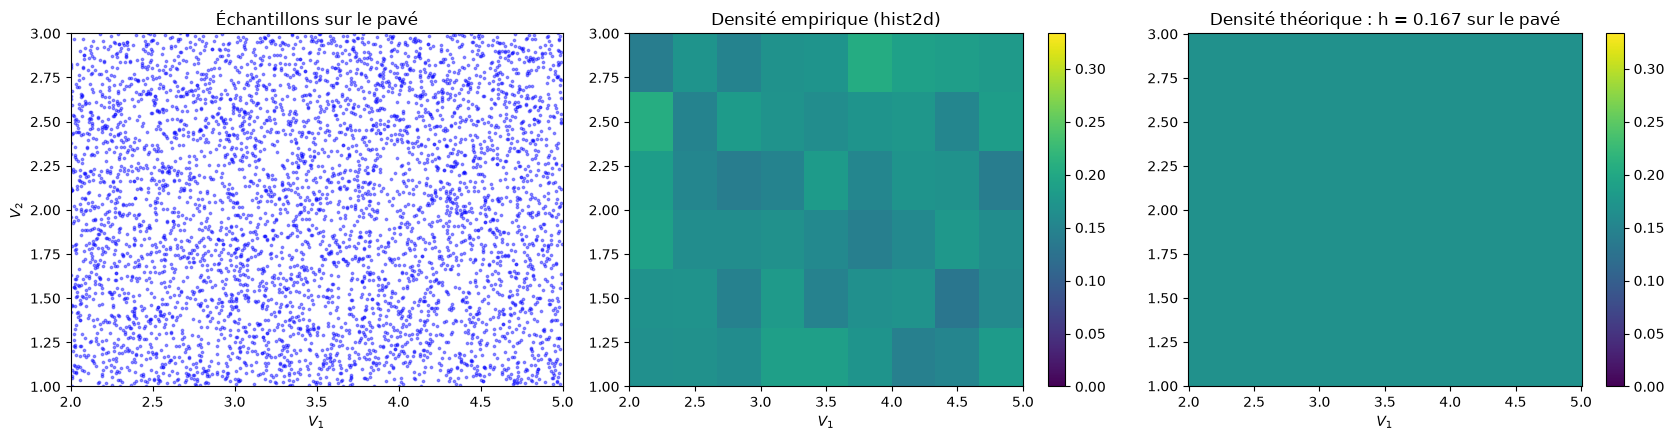

In [37]:
c, d = 1, 3
n = 5000

# Échantillons uniformes sur [0,1]^2 (U1 et U2 indépendantes)
U = rng.uniform(0, 1, size=(n, 2))

# Transformation affine composante par composante : [0,1]^2 -> [a,b] x [c,d]
V = np.column_stack((resample(U[:, 0], a, b), resample(U[:, 1], c, d)))

# Densité théorique : constante h = 1/((b-a)(d-c)) sur le pavé, 0 ailleurs
h = 1 / ((b - a) * (d - c))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1) Nuage de points : les points remplissent le pavé de façon homogène
axes[0].scatter(V[:, 0], V[:, 1], s=3, alpha=0.4, color='b')
axes[0].set_xlim(a, b)
axes[0].set_ylim(c, d)
axes[0].set_title('Échantillons sur le pavé')
axes[0].set_xlabel('$V_1$')
axes[0].set_ylabel('$V_2$')

# 2) Densité empirique : histogramme 2D normalisé sur le pavé
#    (cases de côté 1/3, même échelle de couleurs que la densité théorique)
bins = [int(3 * (b - a)), int(3 * (d - c))]
_, _, _, im = axes[1].hist2d(V[:, 0], V[:, 1], bins=bins, density=True,
                             range=[[a, b], [c, d]],
                             vmin=0, vmax=2 * h, cmap='viridis')
axes[1].set_title('Densité empirique (hist2d)')
axes[1].set_xlabel('$V_1$')
fig.colorbar(im, ax=axes[1])

# 3) Densité théorique évaluée sur une grille du pavé
xg = np.linspace(a, b, 300)
yg = np.linspace(c, d, 300)
Xg, Yg = np.meshgrid(xg, yg)
Zg = h * ((Xg >= a) & (Xg <= b) & (Yg >= c) & (Yg <= d))
im2 = axes[2].pcolormesh(Xg, Yg, Zg, vmin=0, vmax=2 * h, cmap='viridis', shading='auto')
axes[2].set_title(f'Densité théorique : h = {h:.3f} sur le pavé')
axes[2].set_xlabel('$V_1$')
fig.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()

# Commentaire : l'histogramme 2D fluctue autour de h sur tout le pavé, comme la
# densité théorique ; les écarts sont dus au nombre fini d'échantillons.

**Q3**. À partir de $N$ échantillons de loi uniforme sur l'intervalle $[0,1]$, comment obtenir $N$ échantillons de loi uniforme discrète sur $\{1, ..., K\}$ ?

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Votre réponse ici
</div>

### Exercice 2 - Méthode de la transformée inverse

Soit $X$ une variable aléatoire réelle de fonction de répartition $F$ (rappel : $F$ est une fonction croissante de $\mathbb{R}$ dans $[0,1]$, et "càdlàg", mais pas nécessairement bijective). On définit la **fonction inverse généralisée** $F^{-1}$ de $F$ par :
$$\forall~u \in [0,1],~F^{-1}(u) = \inf\{x \in \mathbb{R}, F(x) \geq u\}.$$

Cette fonction conïncide avec l'inverse classique quand $F$ est bijective (attention même si $F$ est continue elle n'est pas nécessairement bijective, il peut y avoir des plateaux). On a la proposition suivante :

<div style="background-color: rgba(255, 0, 0, 0.15); padding: 8px;">

Si $U$ suit la loi uniforme sur l'intervalle $[0,1]$, alors la v.a. $F^{-1}(U)$ a pour fonction de répartition $F$ (et donc la même loi que $X$).
</div>


Cela donne donc la méthode de la **transformée inverse** ; Si l'on connait explicitement la fonction $F^{-1}$, on peut simuler de n'importe quelle variable aléatoire réelle à partir d'un échantillon de loi uniforme.

**Q1**. À l'aide de cette méthode, simuler $N$ échantillons d'une loi exponentielle de paramètre $\lambda$.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

La fonction de répartition de la loi exponentielle de paramètre $\lambda > 0$ est
$$
F(x) = 1 - e^{-\lambda x}, \quad x \geq 0 .
$$

Elle est continue et strictement croissante sur $\mathbb{R}_+$, donc bijective de $\mathbb{R}_+$ dans $[0,1[$. On l'inverse :
$$
u = 1 - e^{-\lambda x} \iff x = -\frac{\ln(1-u)}{\lambda}, \qquad \text{donc} \quad F^{-1}(u) = -\frac{\ln(1-u)}{\lambda}.
$$

D'après la proposition, si $U \sim \mathcal{U}([0,1])$ alors $F^{-1}(U) \sim \mathcal{E}(\lambda)$, de densité $\lambda e^{-\lambda x}\,\mathbb{1}_{x \geq 0}$.

</div>

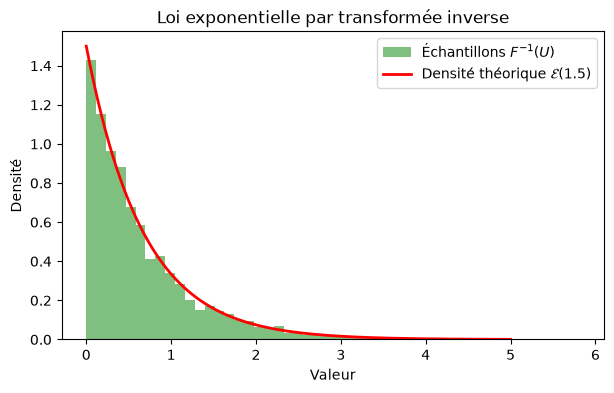

Moyenne empirique : 0.662  (théorique 1/lambda = 0.667)


In [38]:
def F_inv_exp(u, lambda_val):
    """Inverse de la fonction de répartition de la loi exponentielle de paramètre lambda."""
    return -np.log(1 - u) / lambda_val

n = 5000
lambda_val = 1.5

# Échantillons uniformes sur [0,1], puis transformation par F^{-1}
U = rng.uniform(0, 1, n)
X_exp = F_inv_exp(U, lambda_val)

# Densité théorique de la loi exponentielle
x = np.linspace(0, 5, 1000)
dens_th = lambda_val * np.exp(-lambda_val * x)

plt.figure(figsize=(7, 4))
plt.hist(X_exp, bins=50, density=True, alpha=0.5, color='g', label='Échantillons $F^{-1}(U)$')
plt.plot(x, dens_th, 'r-', lw=2, label=f'Densité théorique $\\mathcal{{E}}({lambda_val})$')
plt.title('Loi exponentielle par transformée inverse')
plt.xlabel('Valeur')
plt.ylabel('Densité')
plt.legend()
plt.show()

# Commentaire : l'histogramme suit bien la décroissance exponentielle de la densité théorique.
print(f"Moyenne empirique : {X_exp.mean():.3f}  (théorique 1/lambda = {1 / lambda_val:.3f})")

**Q2**. Quelles sont d'après vous les limitations de la méthode de la transformée inverse ?

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Cette méthode demande de pouvoir calculer $F^{-1}$ explicitement :
- pour beaucoup de lois, $F$ n'a pas d'expression analytique simple (loi normale, loi Bêta, loi Gamma…), et encore moins son inverse ; il faudrait alors inverser $F$ numériquement, ce qui est coûteux et approché ;
- la méthode est propre aux variables **réelles** (1D) : elle ne s'étend pas directement aux vecteurs aléatoires, sauf dans des cas particuliers (composantes indépendantes, ou en passant par les lois conditionnelles).

</div>

### Exercice 3 - Méthode de Box-Müller

On a la proposition suivante :

<div style="background-color: rgba(255, 0, 0, 0.15); padding: 8px;">

Soit $R \sim \text{Exp}(1/2)$ et $\Theta \sim U([0, 2 \pi])$ deux variables aléatoires indépendantes.
    
Alors $X = \sqrt{R} \cos(\Theta)$ et $Y = \sqrt{R} \sin(\Theta)$ sont deux variables indépendantes de loi $\mathcal{N}(0,1)$.
</div>

Cette méthode est connue comme la méthode de **Box-Müller** (1958), et est l'une des méthodes de référence pour générer des variables aléatoires normales.

**Q1 (Bonus)**. Montrer la proposition.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Votre réponse ici
</div>

**Q2**. En déduire une façon de générer un $N$ échantillons de loi normale $\mathcal{N}(0,1)$ à partir d'échantillons d'une loi uniforme sur l'intervalle $[0,1]$.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On tire deux échantillons indépendants $U_1, U_2 \sim \mathcal{U}([0,1])$ et on utilise les résultats précédents :
- $R = F^{-1}(U_1) = -2\ln(1-U_1) \sim \mathcal{E}(1/2)$ (transformée inverse, exercice 2 avec $\lambda = 1/2$) ;
- $\Theta = 2\pi\, U_2 \sim \mathcal{U}([0, 2\pi])$ (exercice 1).

$R$ et $\Theta$ sont indépendantes, donc d'après la proposition
$$
X = \sqrt{R}\cos\Theta, \qquad Y = \sqrt{R}\sin\Theta
$$
sont deux variables indépendantes de loi $\mathcal{N}(0,1)$. Chaque paire $(U_1, U_2)$ donne donc **deux** échantillons gaussiens.

</div>

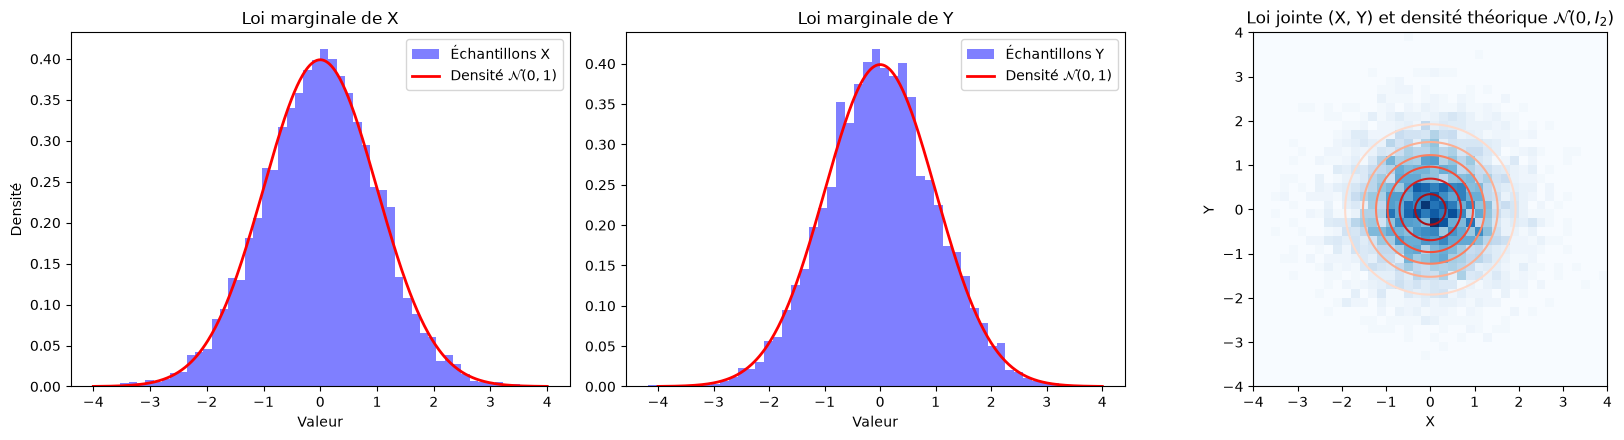

Corrélation empirique entre X et Y : -0.011


In [39]:
def generate_normal_samples(n):
    """Box-Müller : renvoie deux vecteurs indépendants de n échantillons N(0,1)."""
    # Deux échantillons uniformes indépendants sur [0,1]
    U1 = rng.uniform(0, 1, n)
    U2 = rng.uniform(0, 1, n)

    # R ~ Exp(1/2) par transformée inverse
    R = F_inv_exp(U1, 1 / 2)

    # Theta ~ U([0, 2pi]) par transformation affine
    theta = 2 * np.pi * U2

    # Passage en coordonnées cartésiennes
    X = np.sqrt(R) * np.cos(theta)
    Y = np.sqrt(R) * np.sin(theta)
    return X, Y

def normal_pdf(x, mu=0, sigma=1):
    """Densité de la loi N(mu, sigma^2)."""
    return np.exp(-(x - mu) ** 2 / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi))

n = 5000
X_bm, Y_bm = generate_normal_samples(n)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
x = np.linspace(-4, 4, 500)

# 1) et 2) Lois marginales de X et Y comparées à la densité N(0,1)
for ax, samples, name in zip(axes[:2], (X_bm, Y_bm), ('X', 'Y')):
    ax.hist(samples, bins=50, density=True, alpha=0.5, color='b', label=f'Échantillons {name}')
    ax.plot(x, normal_pdf(x), 'r-', lw=2, label='Densité $\\mathcal{N}(0,1)$')
    ax.set_title(f'Loi marginale de {name}')
    ax.set_xlabel('Valeur')
    ax.legend()
axes[0].set_ylabel('Densité')

# 3) Loi jointe : histogramme 2D + lignes de niveau de la densité théorique N(0, I_2)
axes[2].hist2d(X_bm, Y_bm, bins=40, range=[[-4, 4], [-4, 4]], density=True, cmap='Blues')
Xg, Yg = np.meshgrid(x, x)
axes[2].contour(Xg, Yg, normal_pdf(Xg) * normal_pdf(Yg), levels=6, cmap='Reds')
axes[2].set_aspect('equal')
axes[2].set_title('Loi jointe (X, Y) et densité théorique $\\mathcal{N}(0, I_2)$')
axes[2].set_xlabel('X')
axes[2].set_ylabel('Y')

plt.tight_layout()
plt.show()

# Commentaire : les marginales suivent bien la courbe de N(0,1), et l'histogramme 2D
# est isotrope (lignes de niveau circulaires), ce qui illustre l'indépendance de X et Y.
print(f"Corrélation empirique entre X et Y : {np.corrcoef(X_bm, Y_bm)[0, 1]:.3f}")

**Q3**. À partir de $N$ échantillons de loi $\mathcal{N}(0,1)$, comment obtenir un $N$ échantillons de loi $\mathcal{N}(\mu, \sigma^2)$ ?

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Si $X \sim \mathcal{N}(0,1)$, on multiplie chaque échantillon par $\sigma$ puis on ajoute $\mu$ :
$$
Y = \mu + \sigma X .
$$

Une transformation affine d'une variable gaussienne reste gaussienne, avec $\mathbb{E}[Y] = \mu + \sigma\,\mathbb{E}[X] = \mu$ et $\mathrm{Var}(Y) = \sigma^2\,\mathrm{Var}(X) = \sigma^2$. Donc $Y \sim \mathcal{N}(\mu, \sigma^2)$.

</div>

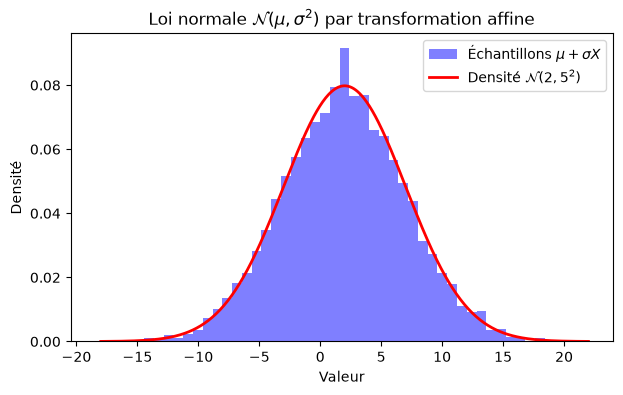

Moyenne empirique : 1.948  (théorique 2)
Écart-type empirique : 5.044  (théorique 5)


In [40]:
def generate_normal_samples_with_params(n, mu, sigma):
    """Renvoie n échantillons N(mu, sigma^2) à partir d'échantillons N(0,1) (Box-Müller)."""
    X, _ = generate_normal_samples(n)  # échantillons N(0,1)
    return mu + sigma * X              # transformation affine

n = 5000
mu, sigma = 2, 5
Y_gauss = generate_normal_samples_with_params(n, mu, sigma)

# Densité théorique de N(mu, sigma^2), tracée sur [mu - 4 sigma, mu + 4 sigma]
x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 500)

plt.figure(figsize=(7, 4))
plt.hist(Y_gauss, bins=50, density=True, alpha=0.5, color='b', label='Échantillons $\\mu + \\sigma X$')
plt.plot(x, normal_pdf(x, mu, sigma), 'r-', lw=2, label=f'Densité $\\mathcal{{N}}({mu}, {sigma}^2)$')
plt.title('Loi normale $\\mathcal{N}(\\mu, \\sigma^2)$ par transformation affine')
plt.xlabel('Valeur')
plt.ylabel('Densité')
plt.legend()
plt.show()

# Commentaire : l'histogramme est centré en mu et a la largeur attendue.
print(f"Moyenne empirique : {Y_gauss.mean():.3f}  (théorique {mu})")
print(f"Écart-type empirique : {Y_gauss.std():.3f}  (théorique {sigma})")

**Q4**. On s'intéresse maintenant à la simulation d'un **vecteur** gaussien en dimension $d$.

Expliquer pourquoi la méthode de Box-Müller permet de simuler des vecteurs de loi $\mathcal{N_d}(\mathbf{0}_d, I_d)$.

Soit $X \sim \mathcal{N_d}(\mathbf{0}_d, I_d)$, $\mathbf{m} \in \mathbb{R}^d$, et $\boldsymbol{\Sigma} \in \mathbb{R}^{d \times d}$ symétrique définie positive. On suppose qu'il existe $\mathbf{L} \in \mathbb{R}^{d \times d}$ tel que $\boldsymbol{\Sigma} = \mathbf{L} \mathbf{L}^{\top}$.

À l'aide des propriétés des vecteurs gaussiens, montrer que $Y = \mathbf{m} + \mathbf{L}X \sim \mathcal{N_d}(\mathbf{m}, \boldsymbol{\Sigma})$.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

**Box-Müller en dimension $d$.** Avec la méthode de Box-Müller, on génère des variables $X_1, \dots, X_d$ **indépendantes** de loi $\mathcal{N}(0,1)$ (en appliquant la méthode $\lceil d/2 \rceil$ fois). Un vecteur dont les composantes sont des gaussiennes indépendantes est un vecteur gaussien, de moyenne $\mathbf{0}_d$ et de covariance $I_d$ (variances égales à 1, covariances nulles par indépendance). Donc $X = (X_1, \dots, X_d) \sim \mathcal{N}_d(\mathbf{0}_d, I_d)$.

**Transformation affine.** Toute transformation affine d'un vecteur gaussien est un vecteur gaussien : $Y = \mathbf{m} + \mathbf{L}X$ est donc gaussien, avec
$$
\mathbb{E}[Y] = \mathbf{m} + \mathbf{L}\,\mathbb{E}[X] = \mathbf{m},
\qquad
\mathrm{Cov}(Y) = \mathbf{L}\,\mathrm{Cov}(X)\,\mathbf{L}^{\top} = \mathbf{L} I_d \mathbf{L}^{\top} = \boldsymbol{\Sigma}.
$$
Un vecteur gaussien est caractérisé par sa moyenne et sa covariance, donc $Y \sim \mathcal{N}_d(\mathbf{m}, \boldsymbol{\Sigma})$.

</div>

**Q5**. On peut montrer qu'une telle matrice $\mathbf{L}$ existe toujours. C'est la **décomposition de Cholesky** ($\mathbf{L}$ est triangulaire inférieure), qui est fondamentale en statistique et *machine learning*. Elle tire son nom d'André-Louis Cholesky, ingénieur polytechnicien, mort pendant la première guerre mondiale (résultat publié de manière posthume en 1924). À noter que la complexité associée à cette décomposition est $\mathcal{O}(d^3)$ !

À partir de $N$ échantillons de loi $\mathcal{N_d}(\mathbf{0}_d, I_d)$, générer $N$ échantillons de loi $\mathcal{N_d}(\mathbf{m}, \boldsymbol{\Sigma})$. Prendre $d=2$ et utiliser `np.linalg.cholesky`.

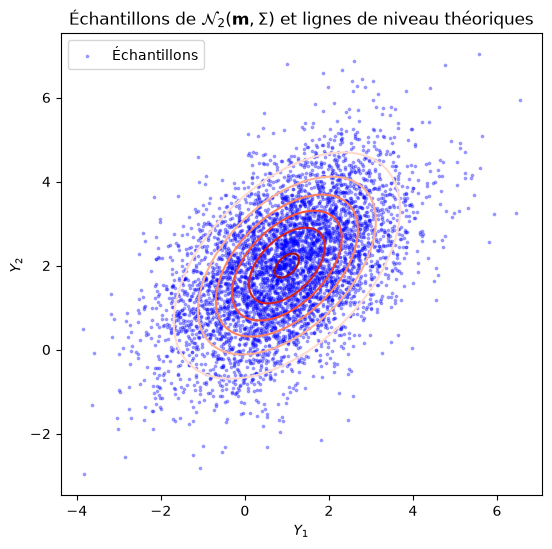

Moyenne empirique : [0.983 1.987]  (théorique [1 2] )
Covariance empirique :
 [[2.042 1.007]
 [1.007 1.976]]
Covariance théorique :
 [[2 1]
 [1 2]]


In [41]:
def generate_multivariate_normal_samples(n, m, Sigma):
    """Renvoie n échantillons de N_2(m, Sigma) : Box-Müller puis Y = m + L X."""
    # X ~ N_2(0, I_2) : les deux sorties de Box-Müller sont N(0,1) indépendantes
    X = np.column_stack(generate_normal_samples(n))   # shape (n, 2)

    # Décomposition de Cholesky : Sigma = L L^T
    L = np.linalg.cholesky(Sigma)

    # Y = m + L X pour chaque échantillon (X est rangé en lignes, d'où X @ L.T)
    return m + X @ L.T

n = 5000
m = np.array([1, 2])
Sigma = np.array([[2, 1], [1, 2]])
Y_vec = generate_multivariate_normal_samples(n, m, Sigma)

# Densité théorique de N_2(m, Sigma) sur une grille
Sigma_inv = np.linalg.inv(Sigma)
xg = np.linspace(m[0] - 4, m[0] + 4, 200)
yg = np.linspace(m[1] - 4, m[1] + 4, 200)
Xg, Yg = np.meshgrid(xg, yg)
D = np.stack((Xg - m[0], Yg - m[1]), axis=-1)            # écarts à la moyenne
quad = np.einsum('...i,ij,...j->...', D, Sigma_inv, D)   # (z - m)^T Sigma^{-1} (z - m)
Zg = np.exp(-quad / 2) / (2 * np.pi * np.sqrt(np.linalg.det(Sigma)))

plt.figure(figsize=(7, 6))
plt.scatter(Y_vec[:, 0], Y_vec[:, 1], s=3, alpha=0.3, color='b', label='Échantillons')
plt.contour(Xg, Yg, Zg, levels=6, cmap='Reds')
plt.gca().set_aspect('equal')
plt.title('Échantillons de $\\mathcal{N}_2(\\mathbf{m}, \\Sigma)$ et lignes de niveau théoriques')
plt.xlabel('$Y_1$')
plt.ylabel('$Y_2$')
plt.legend()
plt.show()

# Commentaire : le nuage est elliptique, orienté selon la diagonale (covariance positive),
# et épouse les lignes de niveau de la densité théorique.
print("Moyenne empirique :", Y_vec.mean(axis=0).round(3), " (théorique", m, ")")
print("Covariance empirique :\n", np.cov(Y_vec.T).round(3))
print("Covariance théorique :\n", Sigma)

### Exercice 4 - Acceptation-Rejet (*Rejection sampling*)

**Q1**. On considère la loi Bêta, dont la densité sur $[0,1]$ est
$$f(x;\alpha, \beta) = \frac{\Gamma(\alpha + \beta)}{\Gamma(\alpha) \Gamma(\beta)} x^{\alpha-1} (1-x)^{\beta-1} \quad \alpha > 0, \quad \beta > 0.$$

On souhaite obtenir des échantillons de la loi Bêta dans le cas suivant : $\alpha = 2, \beta = 2$.
* Expliquer pourquoi il est difficile de mettre en place la méthode de la transformée inverse.
* Quelle loi très simple peut-on utiliser comme loi instrumentale ?
* Implémenter alors un algorithme acceptation-rejet pour obtenir $N = 10000$ échantillons.
* Comparer la proportion empirique d'échantillons acceptés avec sa valeur théorique.
* Quelle difficulté rencontre-t-on pour le cas $\alpha = \beta = 0.5$ ?

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Votre réponse ici
</div>

In [42]:
########
### YOUR CODE HERE
########

**Q2**. On souhaite maintenant obtenir des échantillons d'une loi gaussienne tronquée, i.e., une loi normale restreinte à un certain intervalle (en 1D), ou un certain pavé de l'espace (pour le cas multivarié).

On considère le cas d'une gaussienne multivariée $\mathcal{N}_d(0, I_d)$ que l'on tronque sur le pavé $[-1,2]^d$. On prendra comme loi instrumentale la loi $\mathcal{N}(0, I_d)$ (i.e., non tronquée)

* Justifier ce choix de loi instrumentale.
* Pour le cas univarié ($d=1$), calculer numériquement la probabilité d'acceptation de l'algorithme acceptation-rejet. On pourra utiliser `scipy.stats.cdf`.
* Que devient cette probabilité pour $d=10$ ? $d=100$ ? Conclure quant à la faiblesse fondamentale de l'algorithme acceptation-rejet.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Votre réponse ici
</div>

In [43]:
########
### YOUR CODE HERE
########

### Exercice 5 - Estimation de $\pi$ par Monte Carlo

On rappelle que $\pi$ est égal à la surface d'un cercle de rayon 1, i.e.
$$ \pi = \int_{-1}^1 \int_{-1}^1 \mathbb{1}_{x^2 + y^2 \leq 1}(x,y) dx dy.$$

Ce qui peut se réécrire comme
$$ \pi = 4 \int_{-1}^1 \int_{-1}^1 \mathbb{1}_{x^2 + y^2 \leq 1}(x,y) p(x) p(y) dx dy.$$
Où $p(x)$ et $p(y)$ sont les densités de la loi uniforme sur $[-1,1]$.

* En déduire l'esimtateur de Monte Carlo de $\pi$.
* Générer $N_s = 10000$ échantillons, puis représenter l'évolution de la valeur de l'estimation par Monte Carlo de $\pi$ en ne gardant que les $N$ premiers. Quel résultat fondamental est-on en train d'illustrer ?
* Faire 1000 simulations de l'estimation par Monte Carlo de $\pi$ avec $N_s = 10000$ échantillons, et vérifier le résultat de convergence en loi de l'estimateur de Monte Carlo donné par le TCL.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Votre réponse ici
</div>

In [44]:
########
### YOUR CODE HERE
########

### Exercice 6 - Échantillonnage d'importance (*Importance sampling*)

On cherche à estimer $\mathbb{P}(X > 3)$ avec $X \sim \mathcal{N}(0,1)$.

* Ré-écrire cette probabilité comme une intégrale et en déduire l'estimateur de Monte Carlo "standard".
* Simuler $1000$ fois $N_s = 10000$ échantillons, et calculer la moyenne et la variance empiriques de l'estimateur de Monte Carlo standard.
* On souhaite maintenant implémenter un schéma d'échantillonnage d'importance en utilisant comme loi instrumentale $\mathcal{N}(4,1)$. Donner l'estimateur de Monte Carlo associé.
* De même, simuler $1000$ fois $N_s = 10000$ échantillons, et calculer la moyenne et la variance empiriques de de deuxième estimateur.
* Quantifier la réduction de variance. Commenter.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Votre réponse ici
</div>

In [45]:
########
### YOUR CODE HERE
########